# Rodent–flea species presence across sites

Load the counts for the 51 regions (sites). A species is present at a site when its count is greater than zero. Each species column, including hosts and fleas, contributes once to the distribution.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

data_path = Path("Dataset/rodent_flea/DoublePhyloData_by_region.csv")
regional_data = pd.read_csv(data_path, index_col="Region")
num_sites = len(regional_data)
assert num_sites == 51, f"Expected 51 sites, found {num_sites}"

print(f"Loaded {num_sites} sites and {regional_data.shape[1]} species.")
regional_data.head()

Loaded 51 sites and 327 species.


,Apodemus mystacinus,Apodemus sylvaticus,Chionomys nivalis,Cricetulus migratorius,Dryomys nitedula,Microtus arvalis,Microtus majori,Myoxus glis,Prometheomys schaposchnikowi,Sorex araneus,Allactaga major,Allocricetulus eversmanni,Apodemus uralensis,Arvicola terrestris,Clethrionomys glareolus,Cricetus cricetus,Ellobius talpinus,Lagurus lagurus,Marmota bobak,Microtus gregalis,Microtus oeconomus,Neomys fodiens,Sicista subtilis,Spermophilus major,Spermophilus pygmaeus,Apodemus agrarius,Apodemus speciosus,Clethrionomys rufocanus,Clethrionomys rutilus,Micromys minutus,Microtus agrestis,Sorex arcticus,Sorex caecutiens,Sorex daphaenodon,Sorex isodon,Sorex minutissimus,Sorex minutus,Talpa europaea,Tamias sibiricus,Apodemus peninsulae,...,Phaenopsylla kopetdag,Phaenopsylla tiflovi,Rhadinopsylla altaica,Rhadinopsylla altifrons,Rhadinopsylla angusta,Rhadinopsylla bivirgis,Rhadinopsylla cedestis,Rhadinopsylla dahurica,Rhadinopsylla insolita,Rhadinopsylla integella,Rhadinopsylla ioffi,Rhadinopsylla isacantha,Rhadinopsylla li,Rhadinopsylla pentacantha,Rhadinopsylla pseudodahurica,Rhadinopsylla rothschildi,Rhadinopsylla socia,Rhadinopsylla ucrainica,Rostropsylla daca,Stenoponia conspecta,Stenoponia ivanovi,Stenoponia montana,Stenoponia sidimi,Stenoponia suknevi,Stenoponia tripectinata,Stenoponia vlasovi,Synosternus longispinus,Tarsopsylla octodecimdentata,Wagnerina longicauda,Wagnerina schelkovnikovi,Wagnerina tuvensis,Xenopsylla cheopis,Xenopsylla conformis,Xenopsylla gerbilli,Xenopsylla hirtipes,Xenopsylla magdalinae,Xenopsylla nubica,Xenopsylla nuttalli,Xenopsylla persica,Xenopsylla skrjabini
Region,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Adzharia,375,5051,8,68,34,1345,358,4,382,442,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5,0,0,0,0.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Akmolinsk,0,0,0,6,0,11,0,0,0,17,1,2,3,4,5,7,8,9,10,12,13,15,16,18,19,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0,0,0,0,0,0,25,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Altai,0,0,0,0,0,150,0,0,0,255,0,0,0,21,153,12,0,0,0,25,88,49,86,0,0,102,63,3,90,14,25,39,18,14,4,2,250,5,19,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Amur,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,757,1771,0,0,0,0,0,0,0,0,0,160,161,...,0,0,0,0,0,0,0,0,0,75,0,0,0,0.0,0,0,0,0,0,0,0,56,0,0,0,0,0,16,0,0,0,0,0,0,0,0,0,0,0,0
Amur-Bureya,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2323,1614,0,0,0,0,0,0,0,0,0,19,433,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,11,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## Number of sites where each species is present

Count positive values down each species column, then append the result as the row `num sites present`. Keep the site data separately so rerunning this cell does not include the summary row in the counts.

In [2]:
num_sites_present = regional_data.gt(0).sum(axis=0).astype(int)
data_with_presence = regional_data.copy()
data_with_presence.loc["num sites present"] = num_sites_present

data_with_presence.tail()

,Apodemus mystacinus,Apodemus sylvaticus,Chionomys nivalis,Cricetulus migratorius,Dryomys nitedula,Microtus arvalis,Microtus majori,Myoxus glis,Prometheomys schaposchnikowi,Sorex araneus,Allactaga major,Allocricetulus eversmanni,Apodemus uralensis,Arvicola terrestris,Clethrionomys glareolus,Cricetus cricetus,Ellobius talpinus,Lagurus lagurus,Marmota bobak,Microtus gregalis,Microtus oeconomus,Neomys fodiens,Sicista subtilis,Spermophilus major,Spermophilus pygmaeus,Apodemus agrarius,Apodemus speciosus,Clethrionomys rufocanus,Clethrionomys rutilus,Micromys minutus,Microtus agrestis,Sorex arcticus,Sorex caecutiens,Sorex daphaenodon,Sorex isodon,Sorex minutissimus,Sorex minutus,Talpa europaea,Tamias sibiricus,Apodemus peninsulae,...,Phaenopsylla kopetdag,Phaenopsylla tiflovi,Rhadinopsylla altaica,Rhadinopsylla altifrons,Rhadinopsylla angusta,Rhadinopsylla bivirgis,Rhadinopsylla cedestis,Rhadinopsylla dahurica,Rhadinopsylla insolita,Rhadinopsylla integella,Rhadinopsylla ioffi,Rhadinopsylla isacantha,Rhadinopsylla li,Rhadinopsylla pentacantha,Rhadinopsylla pseudodahurica,Rhadinopsylla rothschildi,Rhadinopsylla socia,Rhadinopsylla ucrainica,Rostropsylla daca,Stenoponia conspecta,Stenoponia ivanovi,Stenoponia montana,Stenoponia sidimi,Stenoponia suknevi,Stenoponia tripectinata,Stenoponia vlasovi,Synosternus longispinus,Tarsopsylla octodecimdentata,Wagnerina longicauda,Wagnerina schelkovnikovi,Wagnerina tuvensis,Xenopsylla cheopis,Xenopsylla conformis,Xenopsylla gerbilli,Xenopsylla hirtipes,Xenopsylla magdalinae,Xenopsylla nubica,Xenopsylla nuttalli,Xenopsylla persica,Xenopsylla skrjabini
Region,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Ural Valley,0,0,0,0,0,1920,0,0,0,856,0,9,15198,73,5209,8,13,2,0,0,29,0,5,0,0,0,0,0,0,63,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Ussury,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1028,0,0,0,68,0,0,0,0,0,0,0,0,17,8,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0,4,0,0,0,0,0,0,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Volga-Kama,0,0,0,4,18,2182,0,1,0,3896,9,4,2500,1054,17966,2,0,0,1,0,60,32,8,266,523,244,0,0,231,4,69,0,0,0,0,0,732,225,2,0,...,0,0,0,0,0,0,0,0,0,449,0,0,0,0.0,0,0,0,0,0,0,0,0,0,0,0,0,0,163,0,0,0,0,0,0,0,0,0,0,0,0
Western Sayan,0,0,0,0,0,0,0,0,0,0,0,0,0,4,136,0,0,0,0,0,58,11,0,0,0,0,0,458,1222,0,41,0,0,0,0,0,0,0,248,364,...,0,0,20,0,0,0,0,0,0,26,0,0,0,0.0,7,0,0,0,0,0,0,0,0,0,0,0,0,281,0,0,0,0,0,0,0,0,0,0,0,0
num sites present,1,6,2,19,10,23,2,4,1,20,10,7,23,22,18,10,6,5,3,12,21,16,7,4,6,17,1,15,19,15,15,4,8,3,2,4,11,8,14,10,...,1,1,2,1,3,2,7,5,1,19,1,1,9,2.0,5,5,1,3,2,3,4,3,2,1,2,3,1,10,1,2,1,1,8,4,4,1,0,1,1,3


## Distribution among species

Each bar shows how many species occur at exactly that number of sites (from 0 to 51).

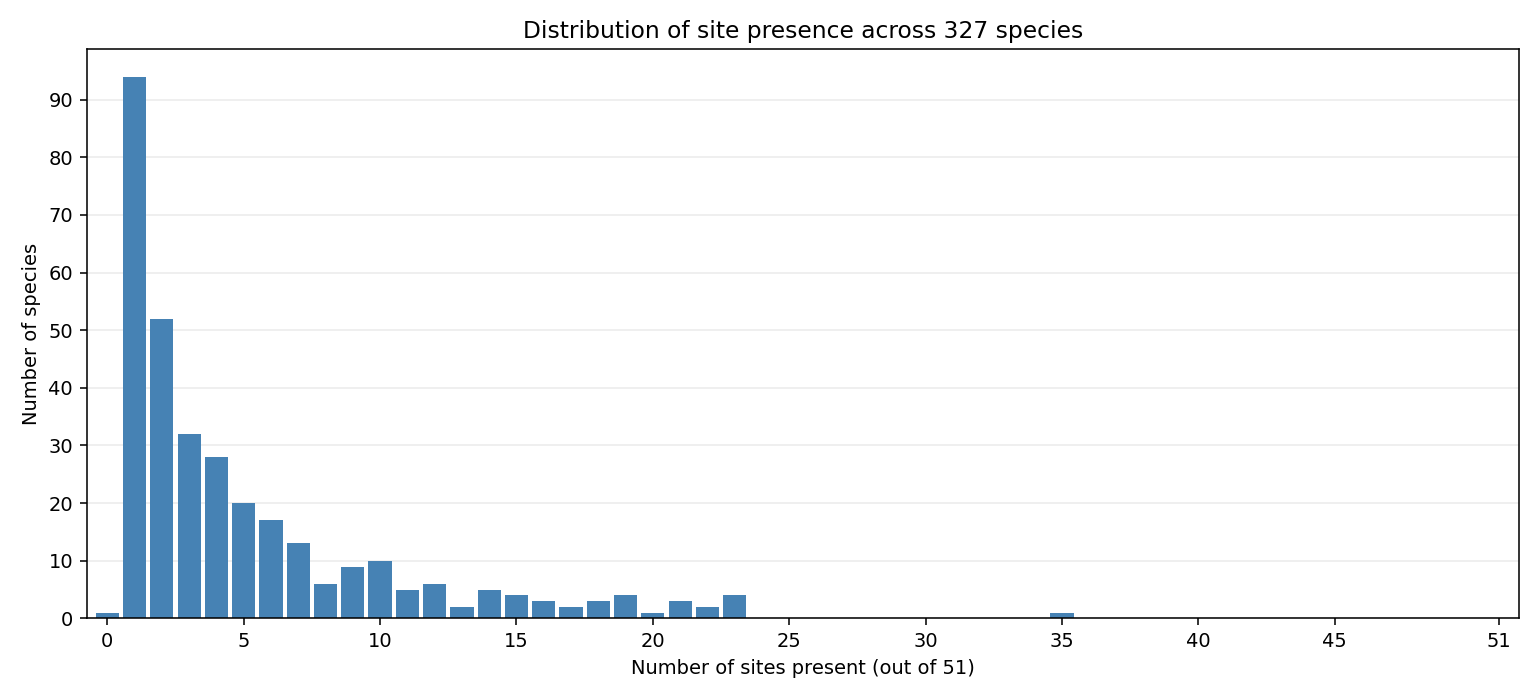

In [3]:
presence_distribution = (
    num_sites_present.value_counts()
    .reindex(range(num_sites + 1), fill_value=0)
    .sort_index()
)

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(
    presence_distribution.index,
    presence_distribution.values,
    width=0.85,
    color="steelblue",
)
ax.set_xlabel(f"Number of sites present (out of {num_sites})")
ax.set_ylabel("Number of species")
ax.set_title(f"Distribution of site presence across {len(num_sites_present)} species")
ax.set_xlim(-0.75, num_sites + 0.75)
ax.set_xticks([0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 51])
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## Column indices of the 10 species present at the most sites

Rank species by `num sites present` in descending order. Print their **zero-based column indices** in `regional_data` (where `Region` is the row index). Ties follow the original column order.

In [4]:
top_10_species = num_sites_present.sort_values(ascending=False, kind="stable").head(10)
top_10_column_indices = regional_data.columns.get_indexer(top_10_species.index).tolist()

print("Column indices of the 10 species with the highest num sites present:")
print(top_10_column_indices)

Column indices of the 10 species with the highest num sites present:
[124, 5, 12, 202, 214, 13, 264, 20, 140, 240]


In [5]:
# Select the 10 species in their original column order, using only site rows.
selected_species_data = regional_data.iloc[:, sorted(top_10_column_indices)].copy()

# Keep regions with at least one nonzero species count; restore Region as a column.
top_10_data = selected_species_data.loc[
    ~selected_species_data.eq(0).all(axis=1)
].reset_index()

print(f"New dataframe shape (rows, columns): {top_10_data.shape}")

New dataframe shape (rows, columns): (48, 11)


In [6]:
print(top_10_data.to_string(index=False))

                       Region  Microtus arvalis  Apodemus uralensis  Arvicola terrestris  Microtus oeconomus  Amalaraeus penicilliger  Amphipsylla rossica  Frontopsylla elata  Hystrichopsylla talpae  Neopsylla pleskei  Palaeopsylla soricis
                     Adzharia              1345                   0                    0                   0                        3                  129                   0                      18                  0                     0
                    Akmolinsk                11                   3                    4                  13                      138                   16                  25                      15                158                    16
                        Altai               150                   0                   21                  88                      136                    0                  48                      75                  0                   119
                         Amur           

## Empirical covariance (Gaussian MLE)

Subtract each species column mean across the retained regions. Compute the Gaussian maximum-likelihood covariance estimate as $\widehat{\Sigma}=X_{\mathrm{centered}}^\top X_{\mathrm{centered}}/n$, where $n$ is the number of retained regions (48).

In [7]:
X = top_10_data.drop(columns="Region")
X_centered = X - X.mean(axis=0)

# Gaussian MLE: divide by n, the number of retained regions.
empirical_covariance = (X_centered.T @ X_centered) / len(X)

empirical_covariance

,Microtus arvalis,Apodemus uralensis,Arvicola terrestris,Microtus oeconomus,Amalaraeus penicilliger,Amphipsylla rossica,Frontopsylla elata,Hystrichopsylla talpae,Neopsylla pleskei,Palaeopsylla soricis
Microtus arvalis,435399.164931,6.106339e+05,54990.757812,-7417.406250,131156.409722,78499.757812,2279.967014,64464.768229,-4515.593750,248649.620660
Apodemus uralensis,610633.895833,4.817657e+06,48837.750000,-5492.020833,135223.187500,118253.187500,-7284.583333,47199.145833,-12160.520833,121344.083333
Arvicola terrestris,54990.757812,4.883775e+04,39075.746094,1875.473958,78052.864583,10775.360677,123.804687,28144.188802,246.473958,84427.529948
Microtus oeconomus,-7417.406250,-5.492021e+03,1875.473958,12245.062500,3750.291667,-1470.776042,-723.739583,1240.911458,-752.854167,2492.338542
Amalaraeus penicilliger,131156.409722,1.352232e+05,78052.864583,3750.291667,335146.597222,24854.135417,-2836.361111,102167.885417,1783.458333,297452.440972
Amphipsylla rossica,78499.757812,1.182532e+05,10775.360677,-1470.776042,24854.135417,28738.558594,194.450521,15171.157552,-1334.067708,88847.957031
Frontopsylla elata,2279.967014,-7.284583e+03,123.804687,-723.739583,-2836.361111,194.450521,2867.206597,405.940104,327.989583,-3482.322049
Hystrichopsylla talpae,64464.768229,4.719915e+04,28144.188802,1240.911458,102167.885417,15171.157552,405.940104,42734.152344,-1079.046875,116341.878906
Neopsylla pleskei,-4515.593750,-1.216052e+04,246.473958,-752.854167,1783.458333,-1334.067708,327.989583,-1079.046875,5382.562500,-3021.869792
Palaeopsylla soricis,248649.620660,1.213441e+05,84427.529948,2492.338542,297452.440972,88847.957031,-3482.322049,116341.878906,-3021.869792,536114.728733


## Export the covariance matrix

Save the labeled pandas DataFrame as a pickle (`.pkl`), preserving species names and numeric types. Reload it with:

```python
empirical_covariance = pd.read_pickle(
    "Dataset/rodent_flea/top_10_empirical_covariance_mle.pkl"
)
```

In [8]:
covariance_path = data_path.parent / "top_10_empirical_covariance_mle.pkl"
empirical_covariance.to_pickle(covariance_path)
print(f"Saved covariance matrix to {covariance_path}")

Saved covariance matrix to Dataset/rodent_flea/top_10_empirical_covariance_mle.pkl


## Inspect the saved Lambda support recovery result

Load the selected run and use species labels from its `summary.json`. The notebook kernel must have `lambda-support-recovery` installed to unpickle the complete result. Change `result_path` to inspect another run. The support includes diagonal entries; the edge table lists selected off-diagonal positions in Lambda.

In [9]:
import json
from dataclasses import asdict
from pathlib import Path

import pandas as pd
from IPython.display import display

result_path = Path(
    "experiments/output/rodent_flea/"
    "top_10_empirical_covariance_mle_zw_ef4vp/result.pkl"
)
recovery_result = pd.read_pickle(result_path)
run_summary = json.loads((result_path.parent / "summary.json").read_text())
result_species = pd.Index(run_summary["species"])
assert recovery_result.support.shape == (len(result_species), len(result_species))

result_overview = pd.Series({
    "method": recovery_result.method,
    "num_samples": recovery_result.num_samples,
    "num_species": len(result_species),
    "support_scope": recovery_result.curve.support_scope,
    "nested_supports": recovery_result.curve.nested_supports,
    "selected_dimension": recovery_result.selected_dimension,
    "num_off_diagonal_edges": len(recovery_result.selected_edges),
    "fitted_omega": recovery_result.fitted_omega,
    "bootstrap_comparisons_performed": len(recovery_result.bootstrap_comparisons),
}, name="value")
display(result_overview.to_frame())


,value
method,plateau-bootstrap
num_samples,48
num_species,10
support_scope,upper
nested_supports,True
selected_dimension,2
num_off_diagonal_edges,1
fitted_omega,2198.012426
bootstrap_comparisons_performed,0


In [10]:
selected_edge_table = pd.DataFrame([
    {
        "row_index": i,
        "column_index": j,
        "row_species": result_species[i],
        "column_species": result_species[j],
        "Lambda_ij": recovery_result.fitted_lambda[i, j],
    }
    for i, j in recovery_result.selected_edges
], columns=["row_index", "column_index", "row_species", "column_species", "Lambda_ij"])
recovered_support = pd.DataFrame(
    recovery_result.support, index=result_species, columns=result_species
)
recovered_lambda = pd.DataFrame(
    recovery_result.fitted_lambda, index=result_species, columns=result_species
)

print("Selected off-diagonal entries (zero-based indices):")
display(selected_edge_table)
print("Selected support (1 = included, 0 = excluded):")
display(recovered_support.astype(int))
print("Fitted Lambda matrix:")
display(recovered_lambda)


Selected off-diagonal entries (zero-based indices):


,row_index,column_index,row_species,column_species,Lambda_ij
0,1,9,Apodemus uralensis,Palaeopsylla soricis,-0.041318


Selected support (1 = included, 0 = excluded):


,Microtus arvalis,Apodemus uralensis,Arvicola terrestris,Microtus oeconomus,Amalaraeus penicilliger,Amphipsylla rossica,Frontopsylla elata,Hystrichopsylla talpae,Neopsylla pleskei,Palaeopsylla soricis
Microtus arvalis,1,0,0,0,0,0,0,0,0,0
Apodemus uralensis,0,1,0,0,0,0,0,0,0,1
Arvicola terrestris,0,0,1,0,0,0,0,0,0,0
Microtus oeconomus,0,0,0,1,0,0,0,0,0,0
Amalaraeus penicilliger,0,0,0,0,1,0,0,0,0,0
Amphipsylla rossica,0,0,0,0,0,1,0,0,0,0
Frontopsylla elata,0,0,0,0,0,0,1,0,0,0
Hystrichopsylla talpae,0,0,0,0,0,0,0,1,0,0
Neopsylla pleskei,0,0,0,0,0,0,0,0,1,0
Palaeopsylla soricis,0,0,0,0,0,0,0,0,0,1


Fitted Lambda matrix:


,Microtus arvalis,Apodemus uralensis,Arvicola terrestris,Microtus oeconomus,Amalaraeus penicilliger,Amphipsylla rossica,Frontopsylla elata,Hystrichopsylla talpae,Neopsylla pleskei,Palaeopsylla soricis
Microtus arvalis,-0.044361,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Apodemus uralensis,0.000000,-1.025018,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.041318
Arvicola terrestris,0.000000,0.000000,-0.028764,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Microtus oeconomus,0.000000,0.000000,0.000000,-0.068759,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Amalaraeus penicilliger,0.000000,0.000000,0.000000,0.000000,0.076753,0.000000,0.000000,0.000000,0.000000,0.000000
Amphipsylla rossica,0.000000,0.000000,0.000000,0.000000,0.000000,0.559661,0.000000,0.000000,0.000000,0.000000
Frontopsylla elata,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.047521,0.000000,0.000000,0.000000
Hystrichopsylla talpae,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.154916,0.000000,0.000000
Neopsylla pleskei,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.056546,0.000000
Palaeopsylla soricis,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.477146


In [11]:
curve_diagnostics = pd.DataFrame({
    "dimension": recovery_result.curve.dimensions,
    "num_off_diagonal_edges": recovery_result.curve.dimensions - 1,
    "valid_fit": recovery_result.curve.support_valid,
    "raw_objective": recovery_result.curve.raw_objectives,
    "screened_objective": recovery_result.screened_objectives,
    "penalty": recovery_result.penalty_values,
    "selected": recovery_result.curve.dimensions == recovery_result.selected_dimension,
})
print("Fitted curve and selected dimension:")
display(curve_diagnostics)

candidate_plateaus = getattr(recovery_result.diagnostics, "plateaus", ())
if candidate_plateaus:
    print("Candidate plateaus:")
    display(pd.DataFrame([asdict(plateau) for plateau in candidate_plateaus]))

bootstrap_comparisons = recovery_result.bootstrap_comparisons
if bootstrap_comparisons:
    print("Bootstrap comparisons:")
    display(pd.DataFrame([
        {key: value for key, value in asdict(comparison).items() if key != "bootstrap_gains"}
        for comparison in bootstrap_comparisons
    ]))
else:
    print("No bootstrap comparisons were performed for this run.")


Fitted curve and selected dimension:


,dimension,num_off_diagonal_edges,valid_fit,raw_objective,screened_objective,penalty,selected
0,1,0,True,2.505416e+13,2.505416e+13,4.516989e+32,False
1,2,1,True,1.840259e+12,1.840259e+12,6.387987e+32,True
2,3,2,True,2.600055e+12,2.600055e+12,7.823655e+32,False
3,4,3,True,3.054320e+12,3.054320e+12,9.033978e+32,False
4,5,4,True,2.730781e+12,2.730781e+12,1.010029e+33,False
5,6,5,True,2.406373e+12,2.406373e+12,1.106432e+33,False
6,7,6,True,2.315147e+12,2.315147e+12,1.195083e+33,False
7,8,7,True,7.318080e+12,7.318080e+12,1.277597e+33,False
8,9,8,True,2.537207e+12,2.537207e+12,1.355097e+33,False
9,10,9,True,2.576441e+12,2.576441e+12,1.428397e+33,False


Candidate plateaus:


,dimension,left,right,center,log_width,persistence_score
0,2,7.322172e-22,1.240723e-19,9.531415e-21,5.132543,5.132543


No bootstrap comparisons were performed for this run.
